In [2]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Python310\python.exe -m pip install --upgrade pip' command.


In [8]:
import pandas as pd

In [9]:
import seaborn as sns

In [11]:
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


In [17]:
import pandas as pd

In [18]:
import matplotlib.pyplot as plt

In [19]:
import seaborn as sns

In [20]:
sns.set_theme(style="whitegrid")

In [21]:
df = pd.read_csv("data/cleaned_data.csv")

In [22]:
print("dataset loaded successfully")
print(df.shape)
print(df.columns.tolist())

dataset loaded successfully
(536641, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [24]:
print(df[["InvoiceNo","InvoiceDate"]].head())

  InvoiceNo          InvoiceDate
0    536365  2010-12-01 08:26:00
1    536365  2010-12-01 08:26:00
2    536365  2010-12-01 08:26:00
3    536365  2010-12-01 08:26:00
4    536365  2010-12-01 08:26:00


In [25]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [28]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

In [30]:
monthly_revenue = df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()

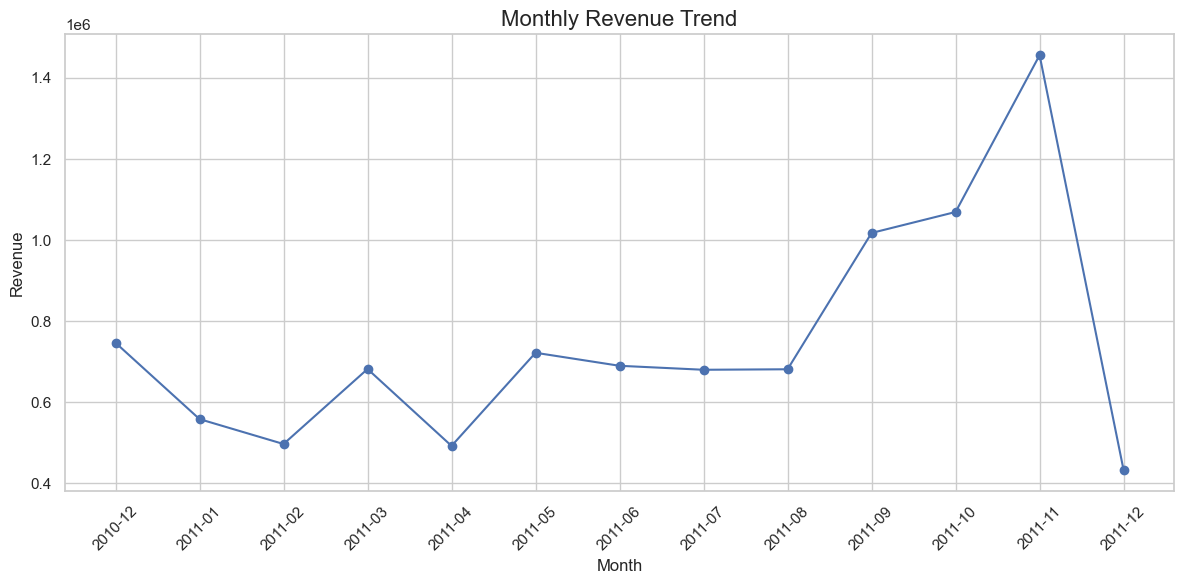

In [31]:
plt.figure(figsize=(12, 6))
plt.plot( monthly_revenue.index.astype(str),monthly_revenue.values,marker="o")
plt.title("Monthly Revenue Trend",fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Business Takeaway

The monthly revenue trend chart shows how sales revenue changes over time. This helps the business identify high-performing and low-performing months.

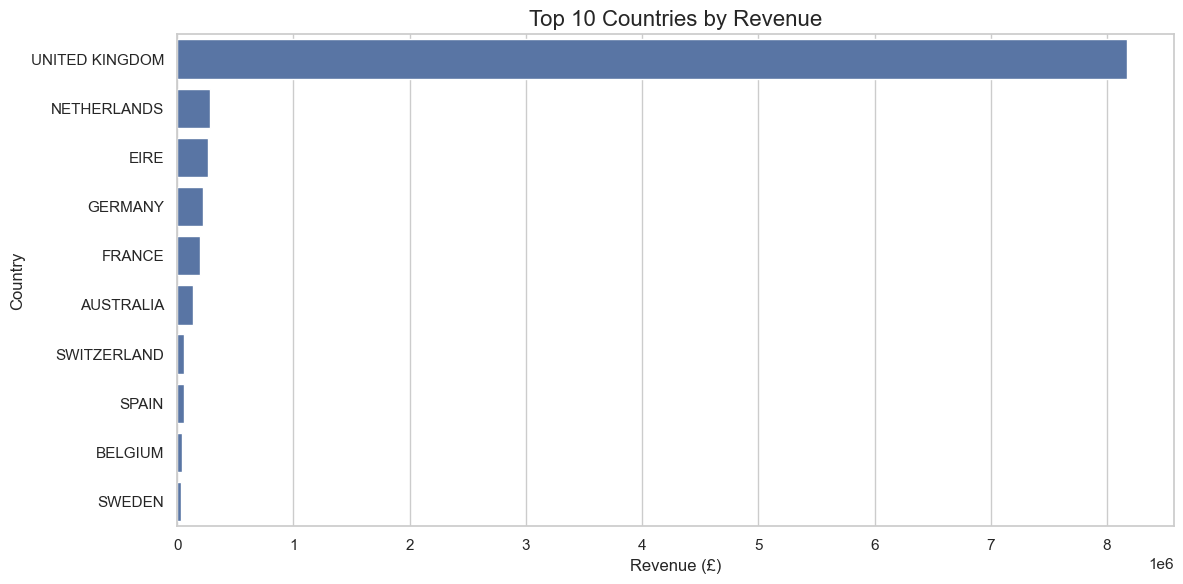

In [33]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

### Business Takeaway

This chart shows the top 10 countries by total revenue. The business can identify its strongest markets and focus on strategies to improve sales in other countries.

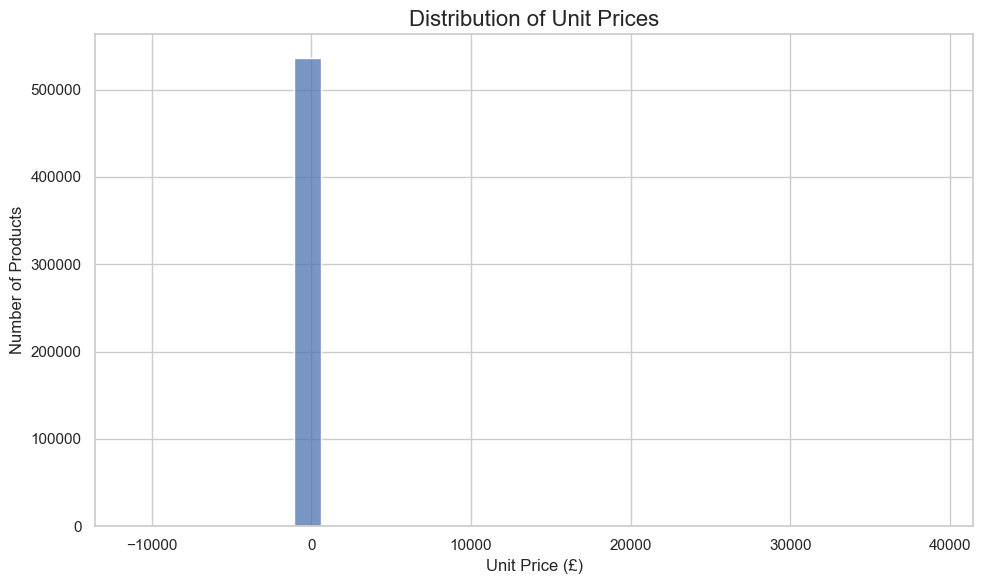

In [34]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="UnitPrice", bins=30)

plt.title("Distribution of Unit Prices", fontsize=16)
plt.xlabel("Unit Price (£)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

Business Takeaway

This histogram shows the distribution of product unit prices. It helps the business understand common product price ranges and identify products 
with unusually high prices.

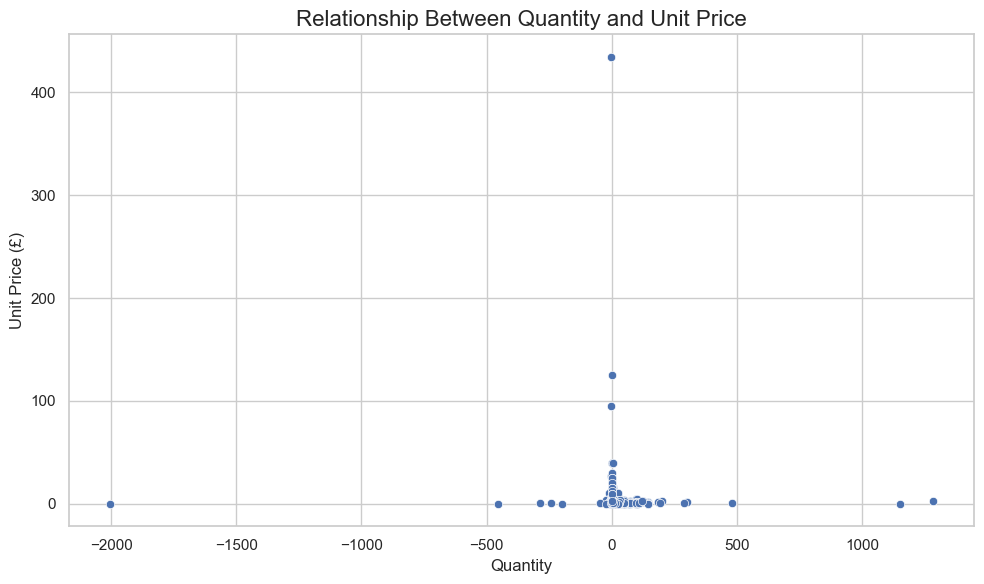

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(min(2000, len(df)), random_state=42),
    x="Quantity",
    y="UnitPrice"
)

plt.title("Relationship Between Quantity and Unit Price", fontsize=16)
plt.xlabel("Quantity")
plt.ylabel("Unit Price (£)")

plt.tight_layout()
plt.show()

Business Takeaway

This chart show the relationship between product quantity and unitprice. It helps the business understand how product price vary across different 
quantites and identify unusual values. 

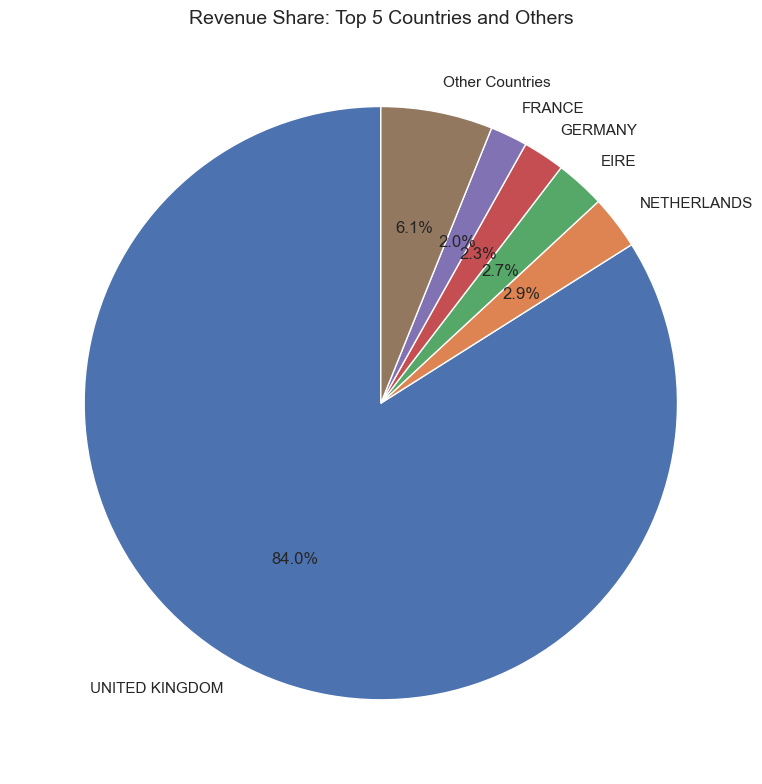

In [37]:
country_sales = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)

top_countries = country_sales.head(5).copy()
top_countries["Other Countries"] = country_sales.iloc[5:].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    top_countries.values,
    labels=top_countries.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share: Top 5 Countries and Others", fontsize=14)
plt.tight_layout()
plt.show()

Business Takeaway

This pie chart shows the contribution of the top five countries and other countries to total revenue. It helps the business understand which markets contribute most to sales and where there may be opportunities for growth.